# stochplace tutorial

This notebook walks through the whole pipeline on a drifting traffic lane:

1. trajectories as points in the `(alpha, p)` line space,
2. intensity estimation and forecasting,
3. sensor placement by void probability,
4. scoring placements on the **true future**, not on the data they were planned on.

It runs in about a minute.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import stochplace as sp

rng = np.random.default_rng(0)
scenario = sp.make_scenario("drift", speed=0.3)
history = scenario.history(8, rng)  # list of (alpha, p) arrays, one per epoch
print([len(a) for a, _ in history], "lines per epoch")

[124, 92, 116, 127, 107, 105, 119, 120] lines per epoch


## 1. Lines are points

A line `x cos(alpha) + y sin(alpha) = p` is the point `(alpha, p)`. The lane drifts, so the cloud of points moves from epoch to epoch.

Out[0]: <matplotlib.legend.Legend at 0x7f070918f4a0>


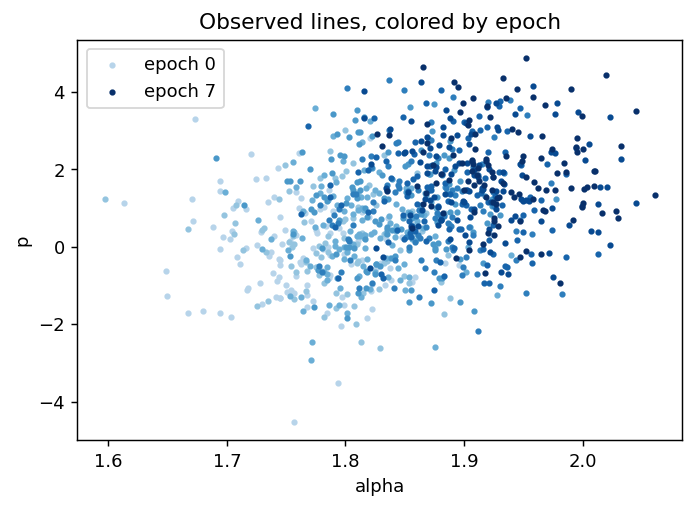

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
for t, (a, p) in enumerate(history):
    ax.scatter(a, p, s=6, color=plt.cm.Blues(0.3 + 0.7 * t / 7), label=f"epoch {t}" if t in (0, 7) else None)
ax.set(xlabel="alpha", ylabel="p", title="Observed lines, colored by epoch")
ax.legend();

## 2. Intensity: history vs forecast

All estimates share one grid. `pooled` uses all history. `stacked` learns simplex weights by the held-out Poisson score of the combined intensity. Every validation origin refits bandwidth on its training prefix. The separate `pseudo_bma` baseline uses individual model scores.

In [3]:
grid = sp.RepGrid(scenario.window, 120, 64)
horizon = 2
pooled = sp.forecast(history, grid, horizon, "pooled")
stacked = sp.forecast(history, grid, horizon, "stacked")
truth = scenario.truth(grid, len(history) - 1 + horizon)
print("stacking weights:", {k: round(v, 3) for k, v in stacked.meta["weights"].items()})
print(f"L1 error vs true future: pooled {pooled.l1(truth):.1f}, stacked {stacked.l1(truth):.1f}")

stacking weights: {'pooled': 0.0, 'recent': 0.0, 'drift_u': 0.834, 'trend': 0.166}
L1 error vs true future: pooled 175.8, stacked 28.4


Out[0]: Text(0, 0.5, 'p')


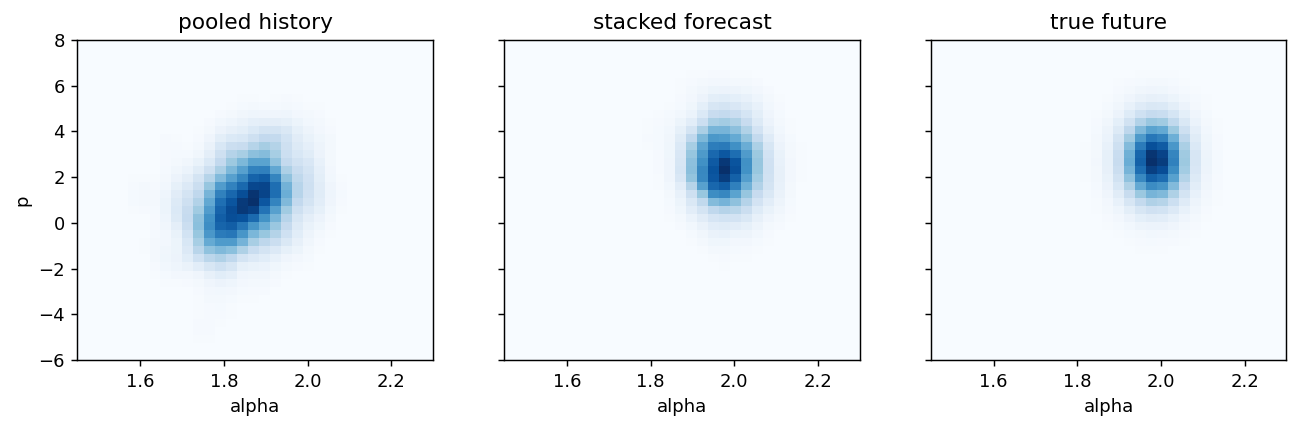

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (f, name) in zip(
    axes, [(pooled, "pooled history"), (stacked, "stacked forecast"), (truth, "true future")]
):
    ax.imshow(
        f.density.T, origin="lower", aspect="auto", cmap="Blues", extent=(0, np.pi, -grid.p_max, grid.p_max)
    )
    ax.set(xlim=(1.45, 2.3), ylim=(-6, 8), title=name, xlabel="alpha")
axes[0].set_ylabel("p");

## 3. Place sensors

Greedy selection on a candidate grid (within `1 - 1/e` of the best subset for the expected objective), then gradient refinement.

In [5]:
model = sp.GaussianSensor(rho=0.95, r=1.0)
cand = scenario.window.grid(1.0)
plans = {
    name: sp.solve(sp.Problem(f, model), cand, 4, scenario.window)
    for name, f in [("pooled", pooled), ("stacked", stacked), ("oracle", truth)]
}
for name, pl in plans.items():
    print(f"{name:8s}", np.round(pl.sensors, 2).tolist())

pooled   [[-5.44, -1.19], [-5.69, 0.03], [-4.5, -2.34], [-6.49, 1.34]]
stacked  [[-0.31, 1.99], [-0.96, 3.0], [0.46, 0.9], [-2.28, 3.95]]
oracle   [[-1.31, 2.98], [-0.86, 1.97], [-1.82, 4.14], [-0.35, 0.81]]


## 4. Score on the future

The oracle is the same heuristic given true future intensity. It is a useful reference, not a certified continuous optimum. A detection fraction is distinct from the chance that no trajectory is missed in an epoch.

In [6]:
for name, pl in plans.items():
    s = sp.score_on_truth(pl.sensors, truth, model)
    print(
        f"{name:8s} detection {100 * s.detection_rate:6.2f}%   P(no ship missed in an epoch) = {s.void_probability:.3g}"
    )

pooled   detection  92.04%   P(no ship missed in an epoch) = 7.12e-05
stacked  detection  95.38%   P(no ship missed in an epoch) = 0.0039
oracle   detection  95.54%   P(no ship missed in an epoch) = 0.00474


## 5. Uncertainty and robust objectives

The expected objective needs only the predictive mean. `void` maximises expected void probability and emphasises favourable futures; it is not a worst-case penalty. `cvar` targets the worst 10% of sampled miss counts, including fractional mass at the quantile. All three are evaluated on the same future truth.

In [7]:
drift_u = sp.forecast(history, grid, horizon, "drift_u")
for obj in ("expected", "void", "cvar"):
    pl = sp.solve(sp.Problem(drift_u, model, objective=obj), cand, 4, scenario.window)
    print(
        f"{obj:8s} detection on true future: {100 * sp.score_on_truth(pl.sensors, truth, model).detection_rate:.2f}%"
    )

expected detection on true future: 95.41%
void     detection on true future: 95.42%
cvar     detection on true future: 95.37%


## 6. A conditional grid robustness certificate

The TV objective allows an adversary to redistribute a declared fraction of traffic mass. Its inner solution is exact on the planning grid. The outer sensor search remains a heuristic, and the certificate applies only when the normalised future grid truth is inside the ambiguity ball.

In [8]:
coarse = sp.RepGrid(scenario.window, 72, 48)
field = sp.forecast(history, coarse, horizon, "stacked")
robust = sp.Problem(field, model, "tv", radius=0.15)
plan = sp.solve(robust, scenario.window.grid(2.5), 4, scenario.window)
adversary = sp.tv_adversary(robust.w_mean, robust.miss(plan.sensors), robust.radius)
future = scenario.truth(coarse, 9)
distance = 0.5 * np.abs(future.mass / future.total() - field.mass / field.total()).sum()
print(f"Grid worst-case detection: {1 - adversary.value / field.total():.2%}")
print(
    f"Future expected detection on same grid: {sp.score_on_truth(plan.sensors, future, model).detection_rate:.2%}"
)
print(f"Future-to-forecast TV distance: {distance:.3f}; radius: {robust.radius:.3f}")
print("Certificate applies to this truth:", bool(distance <= robust.radius))

Grid worst-case detection: 79.17%
Future expected detection on same grid: 95.36%
Future-to-forecast TV distance: 0.121; radius: 0.150
Certificate applies to this truth: True


## 7. A forecast assumption can fail

In `reversal`, the lane reverses after the history ends. The model is not told about the turn. Compare planning on history with extrapolation. This is one illustrative seed; the checked-in stress study uses 20 paired seeds.

In [9]:
reversal = sp.make_scenario("reversal")
past = reversal.history(8, np.random.default_rng(0))
g = sp.RepGrid(reversal.window, 72, 48)
future = reversal.truth(g, 9)
for method in ("pooled", "drift_u", "stacked"):
    f = sp.forecast(past, g, 2, method)
    pl = sp.solve(sp.Problem(f, model), reversal.window.grid(2.5), 4, reversal.window)
    print(
        f"{method:8s}: {sp.score_on_truth(pl.sensors, future, model).detection_rate:.2%} future expected detection"
    )

pooled  : 94.72% future expected detection
drift_u : 89.95% future expected detection
stacked : 91.02% future expected detection
